# IoU Threshold Plot

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
datasets_colors = {'BBBC039':'#FFC0CB',
                   'mnfinder':'#80ED99',
                   'mnDINO_data_01':'#192A56',
                   'mnDINO_data_02':'#00A3FF'}

objects_color = {'Nuc':'#00A3FF',
                 'MN':'#A68CFF'}


In [10]:
path = '/scr/yren/IoUs/results_0.1.csv'
result = pd.read_csv(path)
result.head(5)

,imid,methods,datasets,iou_threshold,f1
0,2022-10-14_U2OS-4,CP-SAM,mnfinder_test,0.1,0.6234
1,2023-05-31_misc-1,CP-SAM,mnfinder_test,0.1,0.5225
2,2023-05-31_misc-HFF-revt-01_s17,CP-SAM,mnfinder_test,0.1,0.9032
3,2023-05-31_misc-HFF-revt-01_s18,CP-SAM,mnfinder_test,0.1,0.7619
4,2023-05-31_misc-HFF-revt-01_s19,CP-SAM,mnfinder_test,0.1,0.8667


# Add a column called iou_threshold, iterate through all csvs and concatenate into one.

In [15]:
df = result.groupby(['methods'])['f1'].mean().reset_index()
df.loc[df.methods == 'mndino', 'methods'] = 'mnDINO'
df

,methods,f1
0,CP-SAM,0.394562
1,MicroNucML,0.151217
2,microSAM,0.027045
3,mnDINO,0.694903


In [18]:
folder_path = '/scr/yren/IoUs'
result_files = [file for file in os.listdir(folder_path) if file.endswith('.csv')]

df_all = pd.DataFrame()
for file in result_files:
    threshold = file.removeprefix('results_').removesuffix('.csv')
    result = pd.read_csv(os.path.join(folder_path, file))
    df = result.groupby(['methods'])['f1'].mean().reset_index()
    df.loc[df.methods == 'mndino', 'methods'] = 'mnDINO'
    df['iou_threshold'] = threshold
    df_all = pd.concat([df_all, df])

In [19]:
df_all

,methods,f1,iou_threshold
0,CP-SAM,0.394562,0.1
1,MicroNucML,0.151217,0.1
2,microSAM,0.027045,0.1
3,mnDINO,0.694903,0.1
0,CP-SAM,0.390813,0.2
1,MicroNucML,0.148416,0.2
2,microSAM,0.020634,0.2
3,mnDINO,0.671897,0.2
0,CP-SAM,0.382594,0.3
1,MicroNucML,0.145306,0.3


In [20]:
df_all.to_csv('/scr/yren/iou_threshold.csv', index=False)

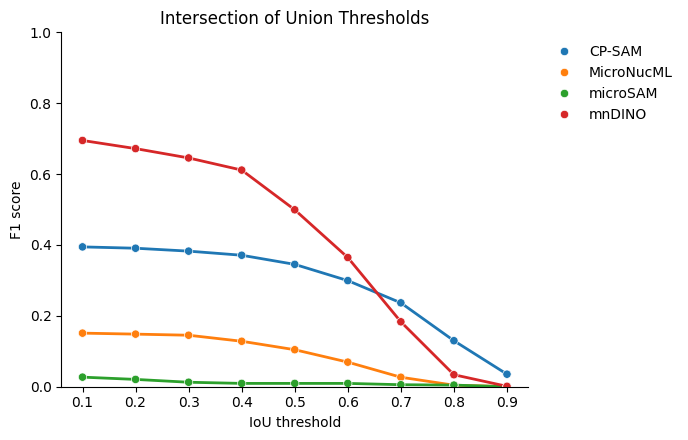

In [21]:
plt.figure(figsize=(7, 4.5))

# Lines only (no markers, no legend of their own)
ax = sns.lineplot(data=df_all, x='iou_threshold', y='f1', hue='methods',
                  linewidth=2, legend=False)

# Dots whose size follows the F1 score
sns.scatterplot(data=df_all, x='iou_threshold', y='f1', hue='methods', ax=ax, zorder=3)

ax.set_xlabel('IoU threshold')
ax.set_ylabel('F1 score')
ax.set_xticks(sorted(df_all['iou_threshold'].unique()))
ax.set_ylim(0, 1)
ax.legend(title=None, bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False)
sns.despine()
plt.title('Intersection of Union Thresholds')
plt.tight_layout()
plt.show()

# IoU Scores

In [9]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [14]:
folder_path = '/scr/yren/IoUs/'
folders = sorted(d for d in os.listdir(folder_path) 
                     if os.path.isdir(os.path.join(folder_path, d)))

folders

['CP-SAM', 'MicroNucML', 'microSAM', 'mndino']

In [15]:
results = []
for folder in folders:
    files = [file for file in os.listdir(os.path.join(folder_path, folder)) if file.endswith('.npy')]
    for file in files:
        imid = os.path.splitext(file)[0]
        iou = np.load(os.path.join(folder_path, folder, file))
        if iou.size == 0:
            iou_score = 0
        else:
            iou_score = np.mean(iou.max(axis=0))
        # 
        if folder == 'mndino':
            name = 'mnDINO'
            item = {'imid':imid, 'method':name, 'iou_score':iou_score}
        else:
            item = {'imid':imid, 'method':folder, 'iou_score':iou_score}
        results.append(item)
        
iou_scores = pd.DataFrame(results, columns=['imid', 'method', 'iou_score'])

In [16]:
iou_scores

,imid,method,iou_score
0,2023-05-31_misc-MCC13_rfpcyto_w1cDAPI_s47,CP-SAM,0.000000
1,20X_c0-DAPI_A1_Tile-130,CP-SAM,0.579594
2,20X_c0-DAPI_A1_Tile-150,CP-SAM,0.471057
3,C1-20X_c0_B3_Tile-15,CP-SAM,0.413332
4,C1-20X_c0_phalloidin_C3_Tile-44,CP-SAM,0.442389
...,...,...,...
251,IXMtest_O02_s4_w1814603DA-DD56-44EF-98C5-AFF3B...,mnDINO,0.128268
252,IXMtest_P07_s8_w144364F25-950A-472C-A529-1A9AD...,mnDINO,0.209524
253,IXMtest_P07_s8_w19D682C29-5685-4A33-8CAA-F0797...,mnDINO,0.199704
254,IXMtest_P15_s8_w1D26A5BC7-CF59-4027-B785-85AD3...,mnDINO,0.276673


In [17]:
df = iou_scores.groupby(['method']).mean('iou_score')
df

,iou_score
method,
CP-SAM,0.282246
MicroNucML,0.140856
microSAM,0.028742
mnDINO,0.393206


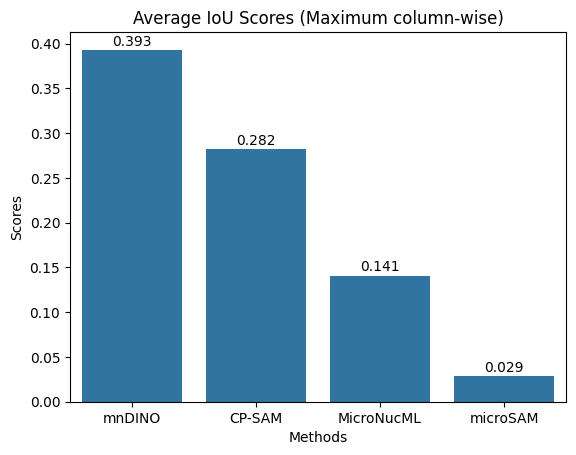

In [18]:
order = df.groupby('method')['iou_score'].mean().sort_values(ascending=False).index
ax = sns.barplot(df, x='method', y='iou_score', order=order)
ax.bar_label(ax.containers[0], fmt='%.3f', padding=1)

plt.title('Average IoU Scores (Maximum column-wise)')
plt.xlabel('Methods')
plt.ylabel('Scores')
plt.show()